# A feedback loop with a communication delay

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/07-delay-budget/notebook.ipynb)

## Goal
The normalized tracking loop is $L(s)=8/[s(s+3)]$. Find gain crossover $\omega_c$, phase margin $\phi_m$ and the first constant pure-delay stability boundary. Introduce delays $T=0.10\,\mathrm{s}$ and $0.30\,\mathrm{s}$. Compare fifth-order Pade approximation with exact phase $-\omega T$, explaining the scope of the rational approximation.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/07-delay-budget/figures/physical-system.png)

A remote mechanism sends measurements and receives commands through a communication path. The model combines those latencies into one ideal constant delay; the drawn packet train is not an experimental record.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/07-delay-budget/exercises.pdf) accompany this model.

## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/07-delay-budget/figures/system-diagram.png)

Constant pure delay shifts a signal in time and contributes frequency-dependent phase lag. The sketch shows ideal steps, not experimental records.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Gain crossover
The open-loop magnitude is $8/[\omega\sqrt{\omega^2+9}]$. Setting it to one and defining $z=\omega^2$ gives $z^2+9z-64=0$, hence

$$
\omega_c=\sqrt{\frac{-9+\sqrt{337}}2}.
$$

The phase is $-90^\circ-\tan^{-1}(\omega/3)$, so the no-delay phase margin is $90^\circ-\tan^{-1}(\omega_c/3)$.
### Delay consumes phase
A pure delay multiplies the loop by $e^{-sT}$. Its frequency magnitude is one and its phase is $-\omega T$ radians. Therefore crossover does not move and

$$
PM(T)=PM(0)-\omega_cT\frac{180}{\pi},\qquad T_{crit}=\frac{PM(0)\pi/180}{\omega_c}.
$$

This is the first imaginary-axis crossing for this stable nominal closed loop with its single positive gain crossover. It is not a universal rule for arbitrary loops with multiple crossings.
### Rational approximation
The fifth-order Pade model approximates the delay by a rational all-pass transfer function. Compare its phase at crossover with the exact phase before using its time response. Artificial right-half-plane zeros and high-order dynamics are approximation features, not physical actuator modes.
### Design decision
Reserve phase for unmodeled sensor and actuator dynamics rather than spending the entire mathematical delay budget. Packet loss, variable delay and sampled-data effects are outside a constant-delay continuous-time approximation.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
loop=ct.tf([8],[1,3,0])
crossover=np.sqrt((-9+np.sqrt(337))/2)
margin0=90-np.degrees(np.arctan(crossover/3))
budget=np.radians(margin0)/crossover
assert abs(abs(ct.evalfr(loop,1j*crossover))-1)<1e-12
time=np.linspace(0,12,4001)
cases=[]
for delay in [0.,.10,.30]:
    approximation=ct.tf(*ct.pade(delay,5)) if delay else ct.tf([1],[1])
    closed=ct.feedback(loop*approximation,1)
    _,output=ct.step_response(closed,time)
    exact_margin=margin0-np.degrees(crossover*delay)
    measured_margin=ct.margin(loop*approximation)[1]
    assert abs(measured_margin-exact_margin)<0.02
    cases.append((delay,output))
    print(f'Delay {delay:.2f} s: exact margin={exact_margin:.6f} deg; Pade margin={measured_margin:.6f} deg')
print(f'Crossover={crossover:.6f} rad/s; ideal delay budget={budget:.6f} s')


Delay 0.00 s: exact margin=54.207784 deg; Pade margin=54.207784 deg
Delay 0.10 s: exact margin=41.814427 deg; Pade margin=41.814427 deg


Delay 0.30 s: exact margin=17.027715 deg; Pade margin=17.027715 deg
Crossover=2.163049 rad/s; ideal delay budget=0.437394 s


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

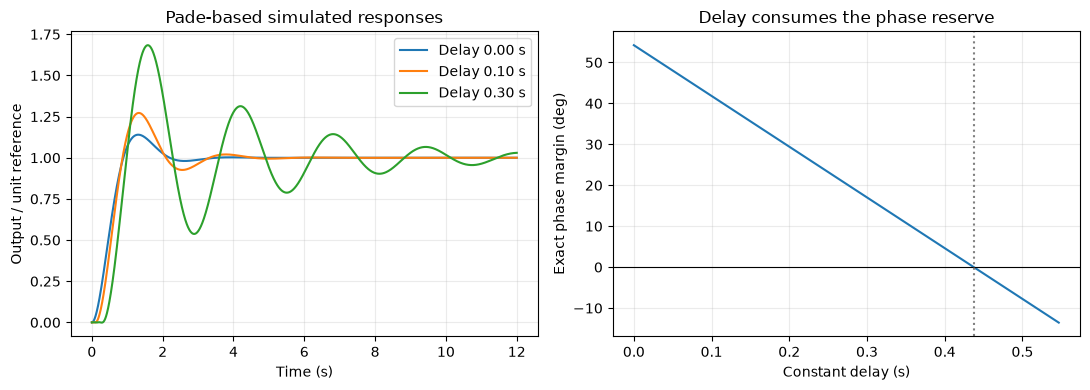

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for delay,output in cases: axes[0].plot(time,output,label=f'Delay {delay:.2f} s')
axes[0].set(xlabel='Time (s)',ylabel='Output / unit reference',title='Pade-based simulated responses'); axes[0].legend()
delays=np.linspace(0,budget*1.25,200)
axes[1].plot(delays,margin0-np.degrees(crossover*delays)); axes[1].axhline(0,color='black',lw=.8)
axes[1].axvline(budget,color='gray',ls=':'); axes[1].set(xlabel='Constant delay (s)',ylabel='Exact phase margin (deg)',title='Delay consumes the phase reserve')
fig.tight_layout()

plt.show()

## Interpret and extend
Exact delay phase supplies the stability-budget calculation. Pade models are checked approximations used to visualize nominal responses.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)